# Assignment: Exploring and Preparing Data

**Name:** Margaret Gonzalez
**Course:** Data Science
**Data set:** `streaming.csv`, movies and TV shows across five streaming services

The CSV is loaded with a relative path, so this notebook runs as long as
`streaming.csv` sits in the same folder as the notebook file.

## Setup

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Relative path, so the file is expected in the same folder as this notebook
streaming = pd.read_csv("streaming.csv")

## 1. Display the first ten rows

In [2]:
streaming.head(10)

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
0,e1,Max,Movie,Jarhead,NaN,"Biography, Drama, War",Biography,2005.0,7.0,214552.0
1,e2,Max,Movie,Unforgiven,NaN,"Drama, Western",Drama,1992.0,8.2,451533.0
2,e3,Max,Movie,Eternal Sunshine of the Spotless Mind,NaN,"Drama, Romance, Sci-Fi",Drama,2004.0,8.3,1128342.0
3,e4,Max,Movie,2001: A Space Odyssey,NaN,"Adventure, Sci-Fi",Adventure,1968.0,8.3,748463.0
4,e5,Max,Movie,Absolute Power,NaN,"Action, Crime, Drama",Action,1997.0,6.7,62416.0
5,e6,Max,Movie,Billy Elliot,NaN,"Drama, Music",Drama,2000.0,7.7,147447.0
6,e7,Max,Movie,American History X,NaN,"Crime, Drama",Crime,1998.0,8.5,1224909.0
7,e8,Max,Movie,Mars Attacks!,NaN,"Comedy, Sci-Fi",Comedy,1996.0,6.4,251058.0
8,e9,Max,Movie,Before Sunrise,NaN,"Drama, Romance",Drama,1995.0,8.1,356144.0
9,e10,Max,Movie,Blade Runner,NaN,"Action, Drama, Sci-Fi",Action,1982.0,8.1,849531.0


## 2. Number of rows and columns using shape

In [3]:
streaming.shape

(23523, 10)

In [4]:
print("Rows:", streaming.shape[0])
print("Columns:", streaming.shape[1])

Rows: 23523
Columns: 10


## 3. Basic details using info()

In [5]:
streaming.info()

<class 'pandas.DataFrame'>
RangeIndex: 23523 entries, 0 to 23522
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   23523 non-null  str    
 1   streaming_service    23523 non-null  str    
 2   type                 23523 non-null  str    
 3   title                20737 non-null  str    
 4   available_countries  64 non-null     str    
 5   listed_in            23523 non-null  str    
 6   main_genre           23523 non-null  str    
 7   release_year         23452 non-null  float64
 8   imdb_rating          20010 non-null  float64
 9   imdb_num_votes       20010 non-null  float64
dtypes: float64(3), str(7)
memory usage: 1.8 MB


### How many variables contain missing values?

**Five variables contain missing values.** The data frame has 23,523 rows, and five of
the ten columns report a non-null count below that total: `title` (20,737 non-null),
`available_countries` (64 non-null), `release_year` (23,452 non-null), `imdb_rating`
(20,010 non-null), and `imdb_num_votes` (20,010 non-null). The other five columns,
`id`, `streaming_service`, `type`, `listed_in`, and `main_genre`, are complete.

### Which variable has the most missing values?

**`available_countries`.** It has only 64 non-null values out of 23,523 rows, which
means 23,459 values are missing, or 99.7 percent of the column. Nothing else comes
close. The next worst are `imdb_rating` and `imdb_num_votes` at 3,513 missing each,
followed by `title` at 2,786 and `release_year` at 71.

In [6]:
# Confirming the two answers above with a direct count
missing = streaming.isna().sum()
print(missing)
print()
print("Variables containing missing values:", (missing > 0).sum())
print("Variable with the most missing values:", missing.idxmax(), "|", missing.max(), "missing")

id                         0
streaming_service          0
type                       0
title                   2786
available_countries    23459
listed_in                  0
main_genre                 0
release_year              71
imdb_rating             3513
imdb_num_votes          3513
dtype: int64

Variables containing missing values: 5
Variable with the most missing values: available_countries | 23459 missing


## 4. info() again, with the non-null counts hidden

In [7]:
streaming.info(show_counts=False)

<class 'pandas.DataFrame'>
RangeIndex: 23523 entries, 0 to 23522
Data columns (total 10 columns):
 #   Column               Dtype  
---  ------               -----  
 0   id                   str    
 1   streaming_service    str    
 2   type                 str    
 3   title                str    
 4   available_countries  str    
 5   listed_in            str    
 6   main_genre           str    
 7   release_year         float64
 8   imdb_rating          float64
 9   imdb_num_votes       float64
dtypes: float64(3), str(7)
memory usage: 1.8 MB


## 5. describe() for object (string) variables only

In [8]:
streaming.describe(include="object")

,id,streaming_service,type,title,available_countries,listed_in,main_genre
count,23523,23523,23523,20737,64,23523,23523
unique,23511,5,2,9919,34,889,39
top,e57,Max,Movie,Monster,US,Documentary,Drama
freq,5,9789,16082,19,8,1837,4513


### How many of these variables contain less than one hundred uniques?

**Four of them.** Looking at the `unique` row: `streaming_service` has 5,
`type` has 2, `available_countries` has 34, and `main_genre` has 39. The remaining
three are far above the threshold, with `id` at 23,511, `title` at 9,919, and
`listed_in` at 889. The four low cardinality columns are the ones that actually behave
like categories and are useful for grouping, while `listed_in` is high cardinality
because it stores a comma separated combination of genres rather than a single value.

In [9]:
object_summary = streaming.describe(include="object")
print(object_summary.loc["unique"])
print()
print("Object variables with fewer than 100 uniques:", (object_summary.loc["unique"] < 100).sum())

id                     23511
streaming_service          5
type                       2
title                   9919
available_countries       34
listed_in                889
main_genre                39
Name: unique, dtype: object

Object variables with fewer than 100 uniques: 4


## 6. Movie and TV show subsets, described with deciles

Passing `percentiles` a list of tenths replaces the default 25th, 50th, and 75th
percentiles with the full set of deciles.

In [10]:
movies = streaming[streaming["type"] == "Movie"]
tv_shows = streaming[streaming["type"] == "TV Show"]

print("Movies:", movies.shape)
print("TV shows:", tv_shows.shape)

Movies: (16082, 10)
TV shows: (7441, 10)


In [11]:
deciles = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

movies.describe(percentiles=deciles).round(3)

,release_year,imdb_rating,imdb_num_votes
count,16081.000,15451.000,15451.000
mean,2008.205,6.479,110399.195
std,17.706,1.021,237460.655
min,1920.000,1.200,5.000
10%,1987.000,5.200,227.000
20%,2000.000,5.700,771.000
30%,2006.000,6.100,1969.000
40%,2010.000,6.300,5872.000
50%,2014.000,6.500,15448.000
60%,2017.000,6.800,38531.000


In [12]:
tv_shows.describe(percentiles=deciles).round(3)

,release_year,imdb_rating,imdb_num_votes
count,7371.000,4559.000,4559.000
mean,2016.265,7.107,23180.950
std,8.799,1.073,101863.423
min,1954.000,1.600,5.000
10%,2007.000,5.800,33.000
20%,2012.000,6.400,77.000
30%,2015.000,6.700,149.000
40%,2017.000,7.000,301.400
50%,2019.000,7.200,591.000
60%,2020.000,7.500,1458.000


### What is the median IMDb rating of a movie?

**6.5.** That is the 50 percent row of the movie `imdb_rating` column. The mean is
6.479, so movie ratings are nearly symmetric and cluster tightly, with the 10th
percentile at 5.2 and the 90th at 7.7.

### Is the movie release year distribution skewed or symmetric?

**It is skewed, specifically left skewed, also called negatively skewed.** The mean
release year is 2008.21 while the median is 2014. When the mean sits below the median,
the longer tail is on the low side, which makes sense here: the bulk of the catalog is
recent, but a thin tail of older films reaching back to 1920 drags the average down
without moving the middle of the distribution. If it were symmetric the two values would
be close to equal.

### What is the IMDb rating's variance for a TV show?

**1.1513.** `describe()` reports standard deviation rather than variance, and the TV
show standard deviation is 1.073. Squaring it gives the variance, confirmed in the cell
below with `var()`.

### What is the most IMDb votes received by a TV show?

**2,410,650 votes.** That is the maximum of the TV show `imdb_num_votes` column, and it
sits far outside the rest of the distribution given that the 90th percentile is only
39,128.8 votes.

In [13]:
print("Median IMDb rating of a movie:", movies["imdb_rating"].median())
print("Movie mean release year:  ", round(movies["release_year"].mean(), 3))
print("Movie median release year:", movies["release_year"].median())
print("TV show IMDb rating variance:", round(tv_shows["imdb_rating"].var(), 4))
print("TV show maximum IMDb votes:", f"{tv_shows['imdb_num_votes'].max():,.0f}")

Median IMDb rating of a movie: 6.5
Movie mean release year:   2008.205
Movie median release year: 2014.0
TV show IMDb rating variance: 1.1513
TV show maximum IMDb votes: 2,410,650


## 7. Counts for ALL entries in the listed_in column

The default display truncates long output with an ellipsis, so `option_context`
temporarily lifts the row limit for this one cell. There are 889 unique genre
combinations.

In [14]:
with pd.option_context("display.max_rows", None):
    print(streaming["listed_in"].value_counts())

listed_in
Documentary                                                              1837
Drama                                                                    1707
Comedy                                                                    974
Reality-TV                                                                803
Comedy, Drama                                                             685
Adventure, Animation, Comedy                                              559
Comedy, Drama, Romance                                                    554
Drama, Romance                                                            519
Comedy, Romance                                                           481
Action, Adventure, Animation                                              420
Crime, Drama, Mystery                                                     390
Reality                                                                   386
Crime, Drama, Thriller                                

## 8. Proportions for the streaming service column, in alphabetical order

In [15]:
streaming["streaming_service"].value_counts(normalize=True).sort_index()

streaming_service
Amazon Prime Video    0.245334
Apple TV+             0.104408
Hulu                  0.076181
Max                   0.416146
Netflix               0.157931
Name: proportion, dtype: float64

Max holds the largest share of the catalog at 41.6 percent, followed by Amazon
Prime Video at 24.5 percent, Netflix at 15.8 percent, Apple TV+ at 10.4 percent, and
Hulu at 7.6 percent. Sorting by index rather than by value is what puts the names in
alphabetical order instead of frequency order.

## 9. Histogram of release year

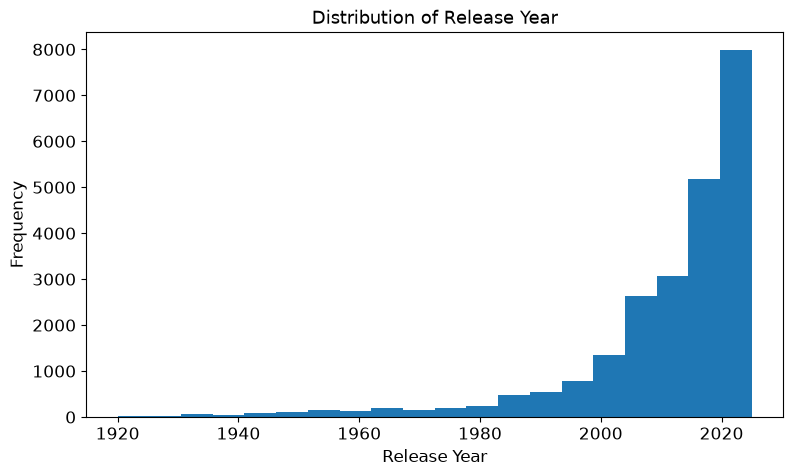

In [16]:
ax = streaming["release_year"].plot(kind="hist", bins=20, figsize=(9, 5))
ax.grid(False)
ax.tick_params(axis="both", labelsize=12)
ax.set_xlabel("Release Year", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_title("Distribution of Release Year", fontsize=13)
plt.show()

### What conclusions can be drawn from the graph?

The distribution is heavily left skewed and strongly concentrated in the last fifteen
years. The tallest bars sit in the late 2010s and early 2020s, while the bins covering
1920 through roughly 1980 are so short they are nearly invisible against the axis. Three
conclusions follow.

First, these catalogs are recency weighted. The median release year is 2016 even though
the range spans 1920 to 2025, so half the library was released in the last nine years of
a 105 year span.

Second, the older titles are not a meaningful part of the collection but they are real.
That thin tail is exactly what pulled the mean below the median in the earlier skewness
question, and it is also what the IQR outlier step later in this assignment will remove.

Third, the drop off at the far right edge is worth noting. The 2025 bar is lower than
2023 and 2024, which is most likely incomplete data for a year still in progress rather
than a genuine decline in production.

## 10. Scatter plot of release year and IMDb votes for movies

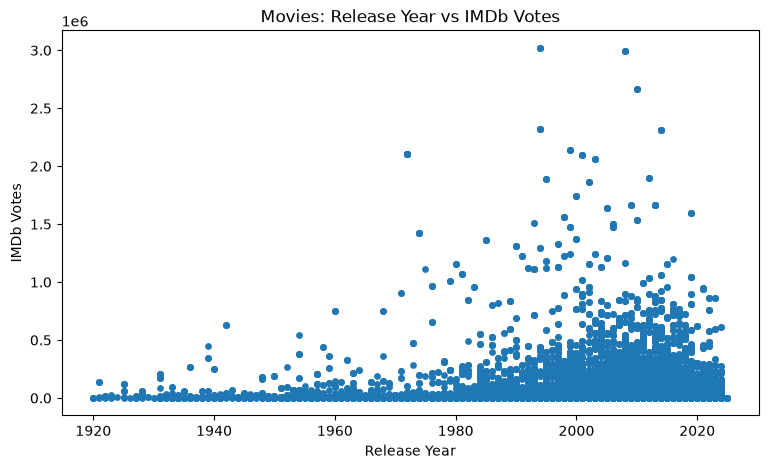

In [17]:
ax = movies.plot(
    kind="scatter",
    x="release_year",
    y="imdb_num_votes",
    s=15,
    figsize=(9, 5),
)
ax.set_xlabel("Release Year")
ax.set_ylabel("IMDb Votes")
ax.set_title("Movies: Release Year vs IMDb Votes")
plt.show()

In [18]:
pearson = movies["release_year"].corr(movies["imdb_num_votes"])
print("Pearson correlation between release year and IMDb votes:", round(pearson, 4))

Pearson correlation between release year and IMDb votes: -0.071


### Is there a strong correlation between the two variables?

**No.** The Pearson correlation is **-0.071**, which is effectively no linear
relationship at all. Anything under roughly 0.3 in absolute value is considered weak, and
this is well below that. The negative sign hints that older movies have accumulated
slightly more votes, which is plausible since they have had more years to collect them,
but the coefficient is far too small to treat as a real effect.

The scatter plot explains why the number is so low. Vote counts are extremely right
skewed, so almost every point is compressed into a flat band near the bottom of the axis
while a handful of blockbusters shoot up past two and three million votes. Those few
extreme points sit at many different release years, so they pull in no consistent
direction. A Pearson coefficient assumes a straight line relationship, and there is no
line here to find.

## 11. Bar chart of main genre counts for TV shows

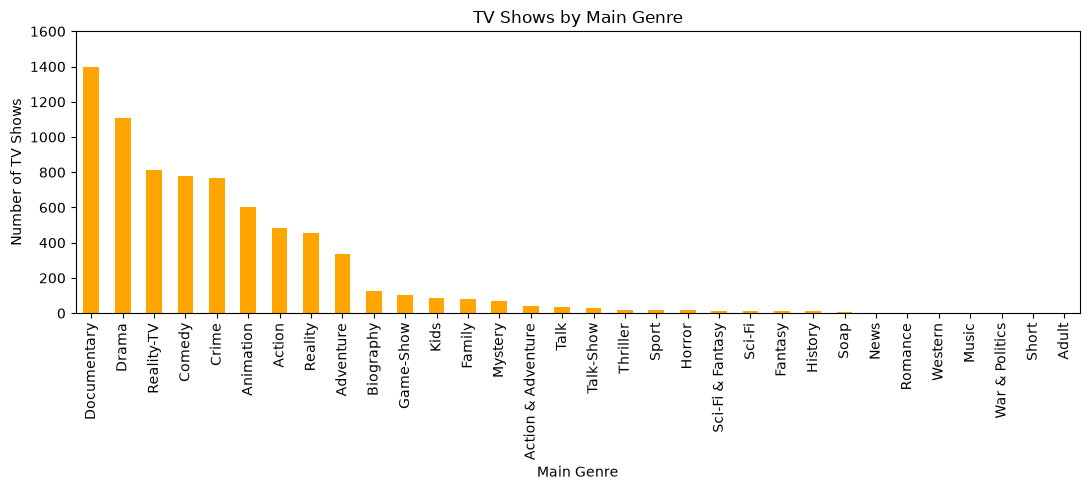

In [19]:
genre_counts = tv_shows["main_genre"].value_counts()

ax = genre_counts.plot(kind="bar", color="orange", figsize=(11, 5))
ax.set_ylim(0, 1600)
ax.set_xlabel("Main Genre")
ax.set_ylabel("Number of TV Shows")
ax.set_title("TV Shows by Main Genre")
plt.tight_layout()
plt.show()

In [20]:
genre_counts.head(5)

main_genre
Documentary    1399
Drama          1106
Reality-TV      813
Comedy          777
Crime           766
Name: count, dtype: int64

### Which genre appears most?

**Documentary**, with 1,399 TV shows. Drama is second at 1,106, then Reality-TV at 813,
Comedy at 777, and Crime at 766. Documentary leading is a little surprising given how
much attention scripted drama gets, and it likely reflects how cheap documentary and
reality content is to license or produce in volume compared to scripted series.

## 12. Movies on Amazon Prime Video with an IMDb rating above 8.5

In [21]:
streaming[
    (streaming["type"] == "Movie")
    & (streaming["streaming_service"] == "Amazon Prime Video")
    & (streaming["imdb_rating"] > 8.5)
]

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
15998,e49831,Amazon Prime Video,Movie,The Lord of the Rings: The Fellowship of the Ring,NaN,"Adventure, Drama, Fantasy",Adventure,2001.0,8.9,2092318.0
15999,e49832,Amazon Prime Video,Movie,The Lord of the Rings: The Two Towers,NaN,"Adventure, Drama, Fantasy",Adventure,2002.0,8.8,1859526.0
16000,e49833,Amazon Prime Video,Movie,The Lord of the Rings: The Return of the King,NaN,"Adventure, Drama, Fantasy",Adventure,2003.0,9.0,2063375.0
16010,e49848,Amazon Prime Video,Movie,The Dark Knight,NaN,"Action, Crime, Drama",Action,2008.0,9.0,2996039.0
16034,e49893,Amazon Prime Video,Movie,The Godfather,NaN,"Crime, Drama",Crime,1972.0,9.2,2107434.0
16035,e49895,Amazon Prime Video,Movie,The Godfather Part II,NaN,"Crime, Drama",Crime,1974.0,9.0,1419319.0
16050,e49921,Amazon Prime Video,Movie,The Shawshank Redemption,NaN,Drama,Drama,1994.0,9.3,3019758.0
16051,e49922,Amazon Prime Video,Movie,Terminator 2: Judgment Day,NaN,"Action, Adventure, Sci-Fi",Action,1991.0,8.6,1223293.0
16069,e49953,Amazon Prime Video,Movie,Seven Samurai,NaN,"Action, Drama",Action,1954.0,8.6,381493.0
16087,e49977,Amazon Prime Video,Movie,Schindler's List,NaN,"Biography, Drama, History",Biography,1993.0,9.0,1511813.0


There are 23 such records, and they read like a list of the most acclaimed films ever
made: The Shawshank Redemption at 9.3, The Godfather at 9.2, and The Dark Knight and
The Return of the King both at 9.0.

## 13. Records containing Fantasy anywhere in listed_in

In [22]:
streaming[streaming["listed_in"].str.contains("Fantasy", na=False)]

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
23,e24,Max,Movie,The Lord of the Rings: The Fellowship of the Ring,NaN,"Adventure, Drama, Fantasy",Adventure,2001.0,8.9,2092318.0
24,e25,Max,Movie,The Lord of the Rings: The Two Towers,NaN,"Adventure, Drama, Fantasy",Adventure,2002.0,8.8,1859526.0
25,e26,Max,Movie,The Lord of the Rings: The Return of the King,NaN,"Adventure, Drama, Fantasy",Adventure,2003.0,9.0,2063375.0
26,e27,Max,Movie,The Lord of the Rings,NaN,"Adventure, Animation, Fantasy",Adventure,1978.0,6.2,37632.0
27,e28,Max,Movie,Princess Mononoke,NaN,"Adventure, Animation, Fantasy",Adventure,1997.0,8.3,455332.0
...,...,...,...,...,...,...,...,...,...,...
23480,e131378,Hulu,TV Show,NaN,NaN,"Drama, Comedy, Sci-Fi & Fantasy",Drama,2015.0,NaN,NaN
23495,e131456,Hulu,TV Show,NaN,NaN,"Animation, Action & Adventure, Sci-Fi & Fantasy",Animation,2004.0,NaN,NaN
23515,e131525,Hulu,TV Show,NaN,NaN,"Action & Adventure, Sci-Fi & Fantasy, Comedy",Action & Adventure,2025.0,NaN,NaN
23518,e131538,Hulu,TV Show,NaN,NaN,"Animation, Sci-Fi & Fantasy, Comedy, Action & ...",Animation,2020.0,NaN,NaN


## 14. Records ending with Fantasy in listed_in

In [23]:
streaming[streaming["listed_in"].str.endswith("Fantasy", na=False)]

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
23,e24,Max,Movie,The Lord of the Rings: The Fellowship of the Ring,NaN,"Adventure, Drama, Fantasy",Adventure,2001.0,8.9,2092318.0
24,e25,Max,Movie,The Lord of the Rings: The Two Towers,NaN,"Adventure, Drama, Fantasy",Adventure,2002.0,8.8,1859526.0
25,e26,Max,Movie,The Lord of the Rings: The Return of the King,NaN,"Adventure, Drama, Fantasy",Adventure,2003.0,9.0,2063375.0
26,e27,Max,Movie,The Lord of the Rings,NaN,"Adventure, Animation, Fantasy",Adventure,1978.0,6.2,37632.0
27,e28,Max,Movie,Princess Mononoke,NaN,"Adventure, Animation, Fantasy",Adventure,1997.0,8.3,455332.0
...,...,...,...,...,...,...,...,...,...,...
23413,e131140,Hulu,TV Show,NaN,NaN,"Kids, Comedy, Sci-Fi & Fantasy",Kids,1984.0,NaN,NaN
23473,e131359,Hulu,TV Show,NaN,NaN,"Animation, Mystery, Sci-Fi & Fantasy",Animation,2024.0,NaN,NaN
23480,e131378,Hulu,TV Show,NaN,NaN,"Drama, Comedy, Sci-Fi & Fantasy",Drama,2015.0,NaN,NaN
23495,e131456,Hulu,TV Show,NaN,NaN,"Animation, Action & Adventure, Sci-Fi & Fantasy",Animation,2004.0,NaN,NaN


`contains()` returns 1,287 records while `endswith()` returns 810. The difference of
477 records is where Fantasy appears in the genre string but is not the final entry, for
example "Action, Fantasy, Adventure". This is the practical distinction between a
substring search anywhere in the value and an anchored match at the end of it.

In [24]:
print("Contains Fantasy anywhere:", streaming["listed_in"].str.contains("Fantasy", na=False).sum())
print("Ends with Fantasy:        ", streaming["listed_in"].str.endswith("Fantasy", na=False).sum())

Contains Fantasy anywhere: 1287
Ends with Fantasy:         810


## 15. Release year of 1940 or earlier, or more than two million IMDb votes

In [25]:
streaming[
    (streaming["release_year"] <= 1940) | (streaming["imdb_num_votes"] > 2_000_000)
]

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
23,e24,Max,Movie,The Lord of the Rings: The Fellowship of the Ring,NaN,"Adventure, Drama, Fantasy",Adventure,2001.0,8.9,2092318.0
25,e26,Max,Movie,The Lord of the Rings: The Return of the King,NaN,"Adventure, Drama, Fantasy",Adventure,2003.0,9.0,2063375.0
36,e37,Max,Movie,The Dark Knight,NaN,"Action, Crime, Drama",Action,2008.0,9.0,2996039.0
52,e53,Max,Movie,Berlin: Symphony of Metropolis,NaN,Documentary,Documentary,1927.0,7.6,4938.0
53,e54,Max,Movie,Bride of Frankenstein,NaN,"Drama, Horror, Sci-Fi",Drama,1935.0,7.8,55551.0
...,...,...,...,...,...,...,...,...,...,...
21795,e121168,Hulu,Movie,The Matrix,NaN,"Action, Sci-Fi",Action,1999.0,8.7,2139791.0
21815,e121193,Hulu,Movie,Pulp Fiction,NaN,"Crime, Drama",Crime,1994.0,8.9,2317096.0
21825,e121204,Hulu,Movie,Gone with the Wind,NaN,"Drama, Romance, War",Drama,1939.0,8.2,344509.0
22068,e121823,Hulu,Movie,Inception,NaN,"Action, Adventure, Sci-Fi",Action,2010.0,8.8,2662920.0


This returns 216 records. The `|` operator is an OR, so a record qualifies by
satisfying either condition, which is why the output mixes very old titles with modern
blockbusters that have enormous vote counts.

## 16. Main genre counts for Netflix movies only

In [26]:
streaming[
    (streaming["streaming_service"] == "Netflix") & (streaming["type"] == "Movie")
]["main_genre"].value_counts()

main_genre
Action         760
Comedy         689
Drama          544
Adventure      227
Crime          210
Biography      155
Horror         140
Animation       46
Documentary     39
Fantasy         14
Family          12
Mystery         11
Thriller        11
Sci-Fi           6
Romance          5
Short            3
Western          2
Music            2
History          1
Sport            1
Adult            1
War              1
TV Movie         1
Name: count, dtype: int64

Action leads with 760 Netflix movies, followed by Comedy at 689 and Drama at 544.
Notice that this is a very different profile from the TV show chart earlier, where
Documentary was first. Netflix's movie library skews toward broad commercial genres.

## 17. Replace missing values in available_countries with "Unknown"

`fillna()` is called on the data frame with a dictionary that targets a single column,
combined with `inplace=True`. That form modifies the existing data frame rather than
returning a copy, which is what the instructions require.

In [27]:
streaming.fillna({"available_countries": "Unknown"}, inplace=True)

print("Missing values remaining in available_countries:",
      streaming["available_countries"].isna().sum())
streaming.head(5)

Missing values remaining in available_countries: 0


,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_num_votes
0,e1,Max,Movie,Jarhead,Unknown,"Biography, Drama, War",Biography,2005.0,7.0,214552.0
1,e2,Max,Movie,Unforgiven,Unknown,"Drama, Western",Drama,1992.0,8.2,451533.0
2,e3,Max,Movie,Eternal Sunshine of the Spotless Mind,Unknown,"Drama, Romance, Sci-Fi",Drama,2004.0,8.3,1128342.0
3,e4,Max,Movie,2001: A Space Odyssey,Unknown,"Adventure, Sci-Fi",Adventure,1968.0,8.3,748463.0
4,e5,Max,Movie,Absolute Power,Unknown,"Action, Crime, Drama",Action,1997.0,6.7,62416.0


## 18. Remove records missing streaming service, title, or release year

In [28]:
streaming.dropna(subset=["streaming_service", "title", "release_year"], inplace=True)

print("Shape after dropping those records:", streaming.shape)

Shape after dropping those records: (20732, 10)


### How many records are there after this procedure?

**20,732 records**, down from 23,523, so 2,791 rows were removed. The column count stays
at 10. Almost all of the loss comes from `title`, which was missing on 2,786 rows.
Restricting `dropna()` to three columns is deliberate. A blanket `dropna()` would also
have keyed on `imdb_rating` and `imdb_num_votes` and thrown away thousands of additional
usable rows.

## 19. Remove release year outliers using the IQR technique

In [29]:
q1 = streaming["release_year"].quantile(0.25)
q3 = streaming["release_year"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = streaming[
    (streaming["release_year"] < lower_bound) | (streaming["release_year"] > upper_bound)
]
print("Outliers identified:", len(outliers))

streaming.drop(outliers.index, inplace=True)

print("Shape after removing outliers:", streaming.shape)

Q1: 2005.0
Q3: 2021.0
IQR: 16.0
Lower bound: 1981.0
Upper bound: 2045.0
Outliers identified: 1303
Shape after removing outliers: (19429, 10)


### How many records are there after removing these outliers?

**19,429 records.** Q1 is 2005 and Q3 is 2021, giving an IQR of 16 years, so the fences
land at 1981 and 2045. That removed 1,303 records, every one of them on the low side,
since no release year can exceed the upper fence of 2045. After this step the earliest
release year in the data frame is 1981.

Worth noting: these are only statistical outliers, not errors. A 1940 film is a real film
with a real release year. The IQR rule flags it as unusual relative to a recency heavy
catalog, and the technique quietly deletes an entire era of cinema. That is a tradeoff
to be aware of rather than an obviously correct cleaning decision.

## 20. Count and drop duplicates

In [30]:
print("Duplicate records:", streaming.duplicated().sum())

streaming.drop_duplicates(inplace=True)

print("Shape after dropping duplicates:", streaming.shape)

Duplicate records: 8
Shape after dropping duplicates: (19421, 10)


**There are 8 duplicates** at this stage, and dropping them brings the data frame to
**19,421 records**. The full file contained 12 exact duplicates before any cleaning, and
4 of those were already eliminated by the missing value and outlier steps.

## 21. Movie subset: IMDb votes in thousands

The movie subset was created earlier and has not been touched by the cleaning steps
above, so it still reflects the original data.

In [31]:
movies = movies.copy()

movies["imdb_votes_thousands"] = movies["imdb_num_votes"] / 1000
movies.drop(columns=["imdb_num_votes"], inplace=True)

movies.head()

,id,streaming_service,type,title,available_countries,listed_in,main_genre,release_year,imdb_rating,imdb_votes_thousands
0,e1,Max,Movie,Jarhead,NaN,"Biography, Drama, War",Biography,2005.0,7.0,214.552
1,e2,Max,Movie,Unforgiven,NaN,"Drama, Western",Drama,1992.0,8.2,451.533
2,e3,Max,Movie,Eternal Sunshine of the Spotless Mind,NaN,"Drama, Romance, Sci-Fi",Drama,2004.0,8.3,1128.342
3,e4,Max,Movie,2001: A Space Odyssey,NaN,"Adventure, Sci-Fi",Adventure,1968.0,8.3,748.463
4,e5,Max,Movie,Absolute Power,NaN,"Action, Crime, Drama",Action,1997.0,6.7,62.416


## 22. Mean IMDb votes in thousands by streaming service, top three

In [32]:
movies.groupby("streaming_service")["imdb_votes_thousands"].mean() \
    .sort_values(ascending=False) \
    .head(3)

streaming_service
Hulu         214.439090
Netflix      143.701060
Apple TV+    130.151373
Name: imdb_votes_thousands, dtype: float64

Hulu leads at roughly 214,439 votes per movie on average, then Netflix at about
143,701 and Apple TV+ at about 130,151. This is a nice illustration of the difference
between size and popularity. Hulu holds the smallest share of the catalog at 7.6 percent
of all titles, yet its movies carry the highest average vote count, meaning it is
licensing a small number of widely watched films rather than a deep back catalog. Max,
which owns 41.6 percent of the catalog, does not even make the top three.

## 23. TV subset: categorize IMDb rating

A helper function handles all four cases in the order the instructions describe them.
The null check has to come first, because a comparison against a missing value would
otherwise return False and quietly fall through to Medium.

In [33]:
tv_shows = tv_shows.copy()


def classify_rating(rating):
    if pd.isna(rating):
        return "Unknown"
    elif rating <= 3:
        return "Low"
    elif rating >= 8:
        return "High"
    else:
        return "Medium"


tv_shows["imdb_rating_class"] = tv_shows["imdb_rating"].apply(classify_rating)
tv_shows.drop(columns=["imdb_rating"], inplace=True)

tv_shows["imdb_rating_class"].value_counts()

imdb_rating_class
Medium     3539
Unknown    2882
High       1001
Low          19
Name: count, dtype: int64

Medium dominates with 3,539 shows, followed by 2,882 Unknown, 1,001 High, and only
19 Low. The Unknown group is the second largest class, which is a reminder of how much of
the TV data has no rating at all. Only 19 shows out of 7,441 rate at 3.0 or below, so
genuinely badly rated television is rare in these catalogs.

## 24. Minimum release year by IMDb rating class

In [34]:
tv_shows.groupby("imdb_rating_class")["release_year"].min().sort_values()

imdb_rating_class
Medium     1954.0
High       1955.0
Unknown    1957.0
Low        2005.0
Name: release_year, dtype: float64

The oldest TV show in each class is Medium at 1954, High at 1955, Unknown at 1957,
and Low at 2005. The interesting result is Low. Every show rated 3.0 or below was
released in 2005 or later, roughly fifty years after the oldest shows in the other three
classes. That is survivorship bias in action. Old television that was poorly received
simply did not survive into a modern streaming catalog, so the only badly rated shows
still available to rate are recent ones.